# Lab 3: Parameter estimation and Unbiasedness of Estimators

## General comments

- At the beginning of the notebook, provide a work breakdown structure estimating the efforts of each team member.
- Submit **both** the Jupyter notebook source (`.ipynb`) **and** its **HTML** export. Name the files `team_x_lab3.ipynb` and `team_x_lab3.html`, replacing `x` with your team number (e.g. `team_07_lab3.ipynb`). Links to GitHub repositories are **NOT** accepted.
- Before you export, restart the kernel, clear all outputs and run all cells. Ensure that all cells ran correctly and there are no errors.
- All formulas **MUST** be written with LaTeX (\$...\$, \$\$...\$\$). Ensure that they are rendered correctly in your `.ipynb` and `.html` submitted files.
- The **team id number** (`ID`) used in the tasks is the ordinal number of your team in the random selection (you can find it in the assignment on the LMS). You **must** fix the random seed at the beginning of your code so that your calculations are reproducible. Draw all random numbers with `np.random` functions (e.g. `np.random.exponential`), after this seed is set.
- Not complying with these instructions may result in a **point deduction**, regardless of whether your implementation is correct.
- At the defence every team member **MUST** understand all tasks and know all derivations, formulas and results in the notebook. Not knowing any of it will result in a **point deduction**.

## Work breakdown

**Team:** N *(put the number of the team)*

| Team member | Tasks |
|---|---|
| _Name Surname_ | _..._ |
| _Name Surname_ | _..._ |
| _Name Surname_ | _..._ |

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
# All your other imports go here

ID = 17  # team id number

# Fix the seed once, at the beginning of the notebook, to make all results reproducible.
# Draw all random numbers with np.random functions (e.g. np.random.exponential(scale=theta, size=(n, m)))
np.random.seed(ID)

---

## Part I: Parameter estimation

**Aim:** In Problems 1 and 2 you have to verify that the interval estimates produced by the known rules really contain the parameter with probability equal to the confidence level.

### Problem 1

The expected value of the exponential distribution $\mathscr{E}(\lambda)$ is $1/\lambda$, so the sample mean $\overline{\mathbf{X}}$ is a good point estimate of the parameter $\theta := 1/\lambda$. A confidence interval for $\theta$ can be formed in several different ways:

1. Using the exact distribution of the statistic $2\lambda n\overline{\mathbf{X}}$ (show that it is $\chi^2_{2n}$, then use the quantiles of the latter to get the interval endpoints).

2. Using the normal approximation $\mathscr{N}(\mu, \sigma^2)$ for $\overline{\mathbf{X}}$, with parameters $\mu = \theta$ and $\sigma^2 = s^2/n$, where $s^2 = \theta^2$ is the population variance (the variance of the original distribution $\mathscr{E}(\lambda)$). In other words, form the $Z$-statistic $Z := \sqrt{n}\,(\overline{\mathbf{X}} - \theta)/\theta$ and use the fact that it is approximately standard normal $\mathscr{N}(0, 1)$:

   $$\mathsf{P}\big(|\theta - \overline{\mathbf{X}}| \le z_\beta\, \theta/\sqrt{n}\big) = \mathsf{P}(|Z| \le z_\beta) = 2\beta - 1,$$

   so $\theta$ lies within $\overline{\mathbf{X}} \pm z_\beta\,\theta/\sqrt{n}$ with probability $2\beta - 1$. (Here $z_\beta$ is the $\beta$-quantile of $\mathscr{N}(0, 1)$).

3. The confidence interval constructed above uses the unknown variance $s^2 = \theta^2$, so it is of little use in practice. Instead, solve the double inequality

   $$|\theta - \overline{\mathbf{X}}| \le z_\beta\, \theta/\sqrt{n}$$

   for $\theta$. This gives another confidence interval that does not depend on the unknown parameter.

4. Another, more universal way to remove the dependence on $\theta$ in (2) is to estimate $s$ by the sample standard deviation and approximate $\overline{\mathbf{X}}$ with the Student $t$-distribution (see Ross's textbook on statistics or the lecture notes for details).

**Task:**

   **(a)** Derive confidence intervals for each of the 4 methods above.

   **(b)** For each method, estimate the actual confidence (the fraction of intervals containing $\theta = 1/\lambda$, which should be close to $1-\alpha$) and the interval lengths. Use $\theta = \texttt{ID}/10$, $\alpha = 0.1;\ 0.05;\ 0.01$, and vary the sample size $n$ and the number of repetitions $m$. Choose convenient visualizations (tables, plots against $n$, etc.) to compare all methods at a glance.

   **(c)** Explain how $n$ and $m$ affect the probability that the parameter lies in each of the four random intervals above, and the lengths of these intervals.

   **(d)** Compare all 4 methods: what are the pros and cons of each, which is the best, and in which cases.


#### Solution

_Your derivations and discussion here._

In [2]:
# Your code here

#### Conclusion

_Your conclusion here._

---

### Problem 2

Repeat parts (2)–(4) of Problem 1 (with the corresponding amendments) for a Poisson distribution $\mathscr{P}(\theta)$.

The **Task** stays the same: derive the intervals, check that they contain the parameter $\theta$ with the prescribed probability, find their lengths, compare the methods and write your conclusions.

#### Solution

_Your derivations and discussion here._

In [3]:
# Your code here

#### Conclusion

_Your conclusion here._

---

## Part II: Unbiasedness of Estimators

### Problem 3

In this task you need to analyze the estimators of the variance and their properties: we will prove the unbiasedness of the variance estimator theoretically and check it in practice!

There are two common estimators of the population variance:
$$
\sigma^2_n = \frac{1}{n}\sum_{i=1}^{n}(X_i - \overline{X})^2,
\qquad
\sigma^2_{n-1} = \frac{1}{n-1}\sum_{i=1}^{n}(X_i - \overline{X})^2.
$$

**Task:**

**(a)** Write code to generate a dataset of i.i.d. samples from $\mathcal{N}(\mu, \sigma^2)$ with $\mu = \texttt{ID}$ and $\sigma^2 = (\texttt{ID} \bmod 5) + 2$, and find the variance of the dataset.

**(b)** Find $\sigma^2_n$ and $\sigma^2_{n-1}$ for $n = 10$, $n = 50$, $n = 100$, $n = 1000$.

**(c)** Find the biases $Bias(\sigma^2_n) = E(\sigma^2_n) - \sigma^2$ and $Bias(\sigma^2_{n-1}) = E(\sigma^2_{n-1}) - \sigma^2$ (estimate the expectations by averaging over many simulated datasets).

**(d)** Comment on the results for the different values of $n$.

**(e)** Derive analytically the expected value of each estimator, $E(\sigma^2_n)$ and $E(\sigma^2_{n-1})$.

**(f)** Using the expected values found above, show mathematically which of the two estimators is unbiased.

**(g)** Comment on the results of the theoretical and practical tasks.

#### Solution

**Parameters:** $\mu = \texttt{ID} = 17$, $\sigma^2 = (17 \bmod 5) + 2 = 4$.

**(a)** We generate a big dataset from $\mathcal{N}(17, 4)$ and compute its variance.

In [4]:
mu = ID
sigma2 = (ID % 5) + 2
sigma = np.sqrt(sigma2)

data = np.random.normal(mu, sigma, size=100_000)
print(f"mu = {mu}, sigma^2 = {sigma2}")
print(f"Variance of the dataset: {np.var(data):.4f}")

mu = 17, sigma^2 = 4
Variance of the dataset: 3.9979


**(b)** One sample for each $n$. We compute both estimators: $\sigma^2_n$ (`ddof=0`) and $\sigma^2_{n-1}$ (`ddof=1`).

In [5]:
import pandas as pd

ns = [10, 50, 100, 1000]
rows = []
for n in ns:
    x = np.random.normal(mu, sigma, size=n)
    rows.append([n, np.var(x, ddof=0), np.var(x, ddof=1)])

pd.DataFrame(rows, columns=["n", "sigma2_n", "sigma2_(n-1)"]).round(4)

,n,sigma2_n,sigma2_(n-1)
0,10,7.0836,7.8706
1,50,3.4577,3.5282
2,100,2.4405,2.4651
3,1000,3.9968,4.0008


**(c)** We estimate $E(\sigma^2_n)$ and $E(\sigma^2_{n-1})$ by averaging over $m = 10\,000$ samples. Then we compute the biases. We also show the theoretical bias of $\sigma^2_n$, which is $-\sigma^2/n$ (see (e)).

In [6]:
m = 10_000
rows = []
for n in ns:
    X = np.random.normal(mu, sigma, size=(m, n))
    E_n  = np.var(X, axis=1, ddof=0).mean()
    E_n1 = np.var(X, axis=1, ddof=1).mean()
    rows.append([n, E_n, E_n1, E_n - sigma2, E_n1 - sigma2, -sigma2 / n])

bias_df = pd.DataFrame(rows, columns=["n", "E(sigma2_n)", "E(sigma2_(n-1))",
                                      "Bias(sigma2_n)", "Bias(sigma2_(n-1))", "Theory bias sigma2_n"])
bias_df.round(4)

,n,E(sigma2_n),E(sigma2_(n-1)),Bias(sigma2_n),Bias(sigma2_(n-1)),Theory bias sigma2_n
0,10,3.5878,3.9865,-0.4122,-0.0135,-0.400
1,50,3.9061,3.9858,-0.0939,-0.0142,-0.080
2,100,3.9677,4.0078,-0.0323,0.0078,-0.040
3,1000,3.9947,3.9987,-0.0053,-0.0013,-0.004


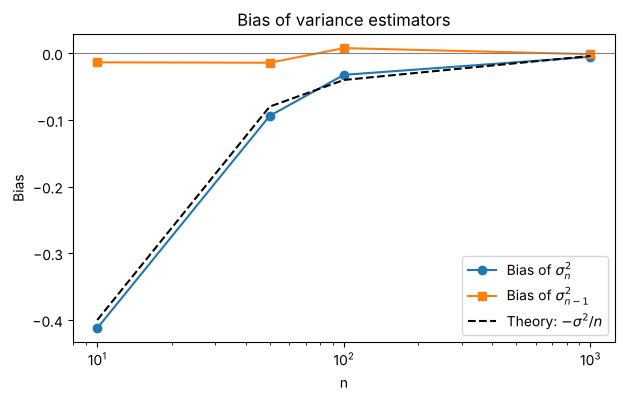

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(ns, bias_df["Bias(sigma2_n)"], "o-", label=r"Bias of $\sigma^2_n$")
plt.plot(ns, bias_df["Bias(sigma2_(n-1))"], "s-", label=r"Bias of $\sigma^2_{n-1}$")
plt.plot(ns, -sigma2 / np.array(ns), "k--", label=r"Theory: $-\sigma^2/n$")
plt.axhline(0, color="gray", lw=0.8)
plt.xscale("log")
plt.xlabel("n")
plt.ylabel("Bias")
plt.title("Bias of variance estimators")
plt.legend()
plt.show()

**(d)** In (b), one sample gives very different values (for example $2.44$ for $n=100$), because one sample is random. So we need the averages from (c) to see the bias.

For small $n$ (e.g. $n=10$), $\sigma^2_n$ is clearly too small on average (bias $\approx -0.4$). The bias of $\sigma^2_{n-1}$ is close to $0$ for every $n$. When $n$ grows, the bias of $\sigma^2_n$ goes to $0$. At $n = 1000$ the two estimators are almost the same.

---

**(e)** Use $\sum_{i=1}^{n}(X_i - \overline{X})^2 = \sum_{i=1}^{n} X_i^2 - n\overline{X}^2$.

We know that $E(X_i^2) = \sigma^2 + \mu^2$ and $E(\overline{X}^2) = \mathrm{Var}(\overline{X}) + \mu^2 = \dfrac{\sigma^2}{n} + \mu^2$. So

$$E\Big[\sum_{i=1}^{n}(X_i - \overline{X})^2\Big] = n(\sigma^2 + \mu^2) - n\Big(\frac{\sigma^2}{n} + \mu^2\Big) = (n-1)\sigma^2.$$

Therefore:

$$E(\sigma^2_n) = \frac{(n-1)\sigma^2}{n} = \sigma^2 - \frac{\sigma^2}{n}, \qquad E(\sigma^2_{n-1}) = \frac{(n-1)\sigma^2}{n-1} = \sigma^2.$$

**(f)**

$$Bias(\sigma^2_n) = -\frac{\sigma^2}{n} \neq 0, \qquad Bias(\sigma^2_{n-1}) = 0.$$

So $\sigma^2_{n-1}$ is **unbiased** and $\sigma^2_n$ is **biased** (it underestimates). The bias of $\sigma^2_n$ goes to $0$ as $n \to \infty$, so it is only *asymptotically* unbiased.

*Why:* $\overline{X}$ is computed from the same data, so the points are always a bit closer to $\overline{X}$ than to $\mu$. We lose one degree of freedom, so we divide by $n-1$.

#### Conclusion

**(g)** The simulation agrees with the theory:

- $\sigma^2_{n-1}$ is unbiased: its average is $\approx \sigma^2 = 4$ for every $n$.
- $\sigma^2_n$ underestimates $\sigma^2$ by about $\sigma^2/n$ (e.g. $-0.4$ for $n=10$).
- For large $n$ the difference is very small, so both estimators work. For small $n$ we should use $\sigma^2_{n-1}$.